### Data Import

In [25]:
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import RandomizedSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor
import matplotlib.pyplot as plt
import seaborn as sns

In [26]:
project_root = Path().resolve()
data_path = Path(project_root/ "data"/ "df_final.csv")

df_train = pd.read_csv(data_path)

In [27]:
data_path2 = Path(project_root/ "data"/ "df_test.csv")

df_test = pd.read_csv(data_path2)

In [28]:
# Quick NaN check on train/test
print("NaN counts (train):")
print(df_train.isna().sum().sort_values(ascending=False).head(10))
print("\nNaN counts (test):")
print(df_test.isna().sum().sort_values(ascending=False).head(10))

NaN counts (train):
montant_engage                   0
naf_grp_Public_admin             0
naf_grp_Water_Waste              0
naf_grp_Transport_Logistics      0
naf_grp_Transport_Equip          0
naf_grp_Trade                    0
naf_grp_Textile                  0
naf_grp_Real_estate              0
naf_grp_Prof_Tech_Sci            0
operateur_type_Financial_fund    0
dtype: int64

NaN counts (test):
montant_engage                   0
naf_grp_Public_admin             0
naf_grp_Water_Waste              0
naf_grp_Transport_Logistics      0
naf_grp_Transport_Equip          0
naf_grp_Trade                    0
naf_grp_Textile                  0
naf_grp_Real_estate              0
naf_grp_Prof_Tech_Sci            0
operateur_type_Financial_fund    0
dtype: int64


In [29]:
X_train = df_train.drop('montant_engage', axis=1)
y_train = df_train['montant_engage']

X_test = df_test.drop('montant_engage', axis=1)
y_test = df_test['montant_engage']

In [30]:
# Check data loading
print("Data Loading Verification:")
print(f"  X_train shape: {X_train.shape}")
print(f"  y_train shape: {y_train.shape}")
print(f"  X_test shape: {X_test.shape}")
print(f"  y_test shape: {y_test.shape}")
print(f"\n  Target statistics:")
print(f"  Train - Min: {y_train.min():,.0f}, Max: {y_train.max():,.0f}, Mean: {y_train.mean():,.0f}")
print(f"  Test  - Min: {y_test.min():,.0f}, Max: {y_test.max():,.0f}, Mean: {y_test.mean():,.0f}")

Data Loading Verification:
  X_train shape: (7094, 69)
  y_train shape: (7094,)
  X_test shape: (1774, 69)
  y_test shape: (1774,)

  Target statistics:
  Train - Min: 288, Max: 11,600,000, Mean: 181,802
  Test  - Min: 425, Max: 8,921,761, Mean: 185,226


In [31]:
# Align train/test feature columns to the common set
train_cols = set(X_train.columns)
test_cols = set(X_test.columns)
common_cols = sorted(train_cols & test_cols)

# Restrict to common columns only (drops any extras)
X_train = X_train[common_cols]
X_test = X_test[common_cols]

print(f"Train columns: {len(train_cols)}, Test columns: {len(test_cols)}, Common: {len(common_cols)}")
missing_train = test_cols - train_cols
missing_test = train_cols - test_cols
if missing_train:
    print("Columns only in test (dropped):", sorted(missing_train))
if missing_test:
    print("Columns only in train (dropped):", sorted(missing_test))

Train columns: 69, Test columns: 69, Common: 69


In [32]:
numeric_cols = X_train.select_dtypes(include=["int64", "Int32", "Int64", 'float64', 'float32']).columns.tolist()

preprocess = ColumnTransformer([
    ("num", "passthrough", numeric_cols),
], remainder="passthrough")

# Create base pipeline for Decision Tree
clf = Pipeline([
    ("prep", preprocess),
    ("model", DecisionTreeRegressor(random_state=42))
])

In [33]:
from sklearn.metrics import r2_score as calculate_r2
clf.fit(X_train, y_train)

from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    "model__max_depth": [8, 10, 12, None],
    "model__min_samples_leaf": [10, 20, 40, 80, 150],
    "model__min_samples_split": [2, 10, 50, 100],
    "model__splitter": ["best"],
    "model__max_features": ["sqrt", "log2", None],
    "model__ccp_alpha": [0.0, 1e-6, 1e-5, 1e-4, 1e-3],
    "model__criterion": ["squared_error", "friedman_mse"]
}

search = RandomizedSearchCV(
    clf,
    param_distributions=param_dist,
    n_iter=200,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    random_state=42,
    verbose=1
)

DecisionTreeRegressor(
    max_depth=7,
    min_samples_leaf=25,
    max_features=None,
    random_state=42
)

search.fit(X_train, y_train)

print("Best params:", search.best_params_)
print(f"CV best R²: {search.best_score_:.4f}")

best_clf = search.best_estimator_
best_y_pred = best_clf.predict(X_test)

from sklearn.metrics import r2_score as calculate_r2
tree_r2 = calculate_r2(y_test.astype('float64'), best_y_pred.astype('float64'))
print(f"Decision Tree test R²: {tree_r2:.4f}")

Fitting 5 folds for each of 200 candidates, totalling 1000 fits
Best params: {'model__splitter': 'best', 'model__min_samples_split': 50, 'model__min_samples_leaf': 40, 'model__max_features': None, 'model__max_depth': None, 'model__criterion': 'squared_error', 'model__ccp_alpha': 1e-05}
CV best R²: 0.1639
Decision Tree test R²: 0.2477


In [34]:
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV
xgb_model = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    tree_method="hist",
    n_estimators=1200,
    n_jobs=-1,
)

xgb_clf = Pipeline([
    ("prep", preprocess),
    ("model", xgb_model),
])

xgb_param_dist = {
    "model__learning_rate": [0.005, 0.01, 0.02, 0.03],
    "model__max_depth": [5, 6, 7, 8],
    "model__min_child_weight": [5, 10, 15],
    "model__subsample": [0.6, 0.7, 0.8],
    "model__colsample_bytree": [0.6, 0.7, 0.8],
    "model__gamma": [0, 0.5, 1, 2],
    "model__reg_alpha": [0, 0.5, 1],
    "model__reg_lambda": [3, 5, 7],
}

xgb_search = RandomizedSearchCV(
    xgb_clf,
    param_distributions=xgb_param_dist,
    n_iter=80,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    random_state=42,
    verbose=1,
)

xgb_search.fit(X_train, y_train)

print("XGB best params:", xgb_search.best_params_)
print(f"XGB CV best R²: {xgb_search.best_score_:.4f}")

best_xgb_clf = xgb_search.best_estimator_
best_xgb_pred = best_xgb_clf.predict(X_test)

from sklearn.metrics import r2_score as calculate_r2
xgb_r2 = calculate_r2(y_test.astype('float64'), best_xgb_pred.astype('float64'))
print(f"XGB test R²: {xgb_r2:.4f}")

Fitting 5 folds for each of 80 candidates, totalling 400 fits
XGB best params: {'model__subsample': 0.6, 'model__reg_lambda': 5, 'model__reg_alpha': 0, 'model__min_child_weight': 15, 'model__max_depth': 8, 'model__learning_rate': 0.005, 'model__gamma': 0.5, 'model__colsample_bytree': 0.8}
XGB CV best R²: 0.2216
XGB test R²: 0.2973


In [ ]:
results_df = pd.DataFrame({
    "ID": df_test.reset_index(drop=True).index,
    "solution": best_xgb_pred
})

print("Results DataFrame (first 10 rows):")
print(results_df.head(10))
print(f"\nShape: {results_df.shape}")

results_df.to_csv('predictions.csv', index=False)

Results DataFrame (first 10 rows):
   ID       solution
0   0  117406.890625
1   1   21958.251953
2   2  115042.429688
3   3  184095.765625
4   4  115364.320312
5   5   51646.406250
6   6  104001.695312
7   7  510655.625000
8   8  195954.890625
9   9  552376.687500

Shape: (1774, 2)


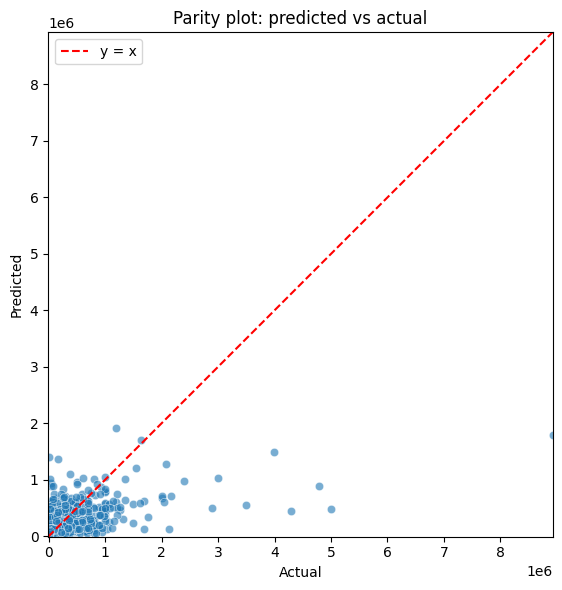

In [ ]:
# Visualization: parity plot (predicted vs actual)
comparison = pd.DataFrame({
    "actual": y_test,
    "pred": best_xgb_pred,
})

plt.figure(figsize=(6, 6))
sns.scatterplot(data=comparison, x="actual", y="pred", alpha=0.6)
lims = [comparison.values.min(), comparison.values.max()]
plt.plot(lims, lims, "r--", label="y = x")
plt.xlim(lims)
plt.ylim(lims)
plt.gca().set_aspect('equal', 'box')
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Parity plot: predicted vs actual")
plt.legend()
plt.tight_layout()
plt.show()